In [3]:
import uproot
import pandas
import numpy as np
import os

import ipympl

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mplColors

uproot.__version__

'5.0.8'

In [4]:
class StyleThing:
  def __init__(self, color, linestyle):
    self.col = color
    self.ls = linestyle
    
class MyStyleSet:
  def __init__(self, option = "nobles"):
    
    # medium types. these are what populate the other arrays 
    self.air = StyleThing('goldenrod', '-')
    
    self.lxe = StyleThing('darkviolet', '-')
    self.lxe2 = StyleThing('fuchsia', '-')

    self.cf4 = StyleThing('deepskyblue', '-')
    # self.cf4_2 = StyleThing('deepskyblue', '-')
    
    self.green = StyleThing('springgreen', '-')
    
    self.red = StyleThing('red', '-')
    
    self.test = StyleThing('#d94ff5', '-')
    
    # line styles
    self.line1 = "-"
    self.line2 = "--"
    self.line3 = ".-"
    
    # all colors
    self.names = [x for x in self.__dict__.keys() if isinstance(self.__dict__[x], StyleThing)]
    self.allColsStr = [x.col for x in self.__dict__.values() if isinstance(x, StyleThing)]
    self.allColsObj = mplColors.to_rgba_array(self.allColsStr).reshape(1, -1, 4)
    
  def show(self):
    fig, ax = plt.subplots(figsize = (len(self.names)*1.5, 2))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(self.allColsObj, aspect=0.5)
    for i, (color, name) in enumerate(zip(self.allColsStr, self.names)):
      txt = f"{name} \n {color}"
      ax.text(i, 0, txt, ha='center', va='center')
    plt.show()
    return

ms = MyStyleSet()
    
    

['air', 'lxe', 'lxe2', 'cf4', 'green', 'red', 'test']


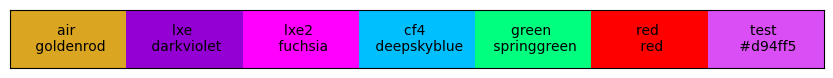

In [6]:
# show it off

ms.lxe.col
print(ms.names)

ms.show()

In [7]:
# # Define your custom style
# plt.rcParams['axes.titlesize'] = 20
# plt.rcParams['axes.labelsize'] = 14
# plt.rcParams['lines.linewidth'] = 2
# plt.rcParams['lines.markersize'] = 10
# plt.rcParams['xtick.labelsize'] = 12
# plt.rcParams['ytick.labelsize'] = 12

# # Define your custom colors
# plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['r', 'g', 'b', 'y'])

# # plt.rcParams.keys()

# my_color = Style(color='r', linestyle='-')
# type(my_color)


In [8]:
# # Create an array of x values
# x = np.linspace(-10, 10, 500)

# print(plt.style.available)
# # plt.style.use('seaborn-')
# # plt.style.use('grayscale')
# plt.style.use('seaborn-v0_8-colorblind')
# # plt.rcParams['lines.alpha'] = 0.
# # vapeplot.set_palette('macplus')

# # Calculate the y values for each function
# y1 = x
# y2 = x**2
# y3 = np.sin(x)
# y4 = np.exp(-x) * np.cos(2*np.pi*x)

# # Create subplots with 2 rows and 2 columns
# fig, axs = plt.subplots(2, 2, figsize=(10, 8))

# # Plot y = x
# axs[0, 0].plot(x, y1, alpha = 1)
# axs[0, 0].plot(x, y1**2)  # Modified version: y = x^2
# axs[0, 0].plot(x, np.cos(x))  # Modified version: y = cos(x)
# axs[0, 0].set_title('y = x')

# # Plot y = x^2
# axs[0, 1].plot(x, y2)
# axs[0, 1].plot(x, np.sqrt(y2))  # Modified version: y = sqrt(x^2)
# axs[0, 1].plot(x, np.tan(x))  # Modified version: y = tan(x)
# axs[0, 1].set_title('y = x^2')

# # Plot y = sin(x)
# axs[1, 0].plot(x, y3)
# axs[1, 0].plot(x, np.cos(y3))  # Modified version: y = cos(sin(x))
# axs[1, 0].plot(x, np.exp(-y3))  # Modified version: y = exp(-sin(x))
# axs[1, 0].set_title('y = sin(x)')

# # Plot the crazy special function
# axs[1, 1].plot(x, y4)
# axs[1, 1].set_title('Crazy Special Function')

# # Adjust the spacing between subplots
# plt.tight_layout()

# # Show the plot
# plt.show()


In [9]:
## loading the data ##
rootPath1 = "../outputs_v1_noImaginary/"
rootPath2 = "../outputs_v2_allPhysics/"

opticsPath_g4 = "../g4PDEsim/dataOptics/"
scintPath_g4 = "../g4PDEsim/data_cf4_scint/"

In [10]:
# useFull = False
# fileAir = uproot.open(os.path.join(rootPath2, "noWindow_air_N1e5_120-1050nm_0-85deg.root"))
# fileCF4 = uproot.open(os.path.join(rootPath2, "noWindow_lcf4_N1e5_120-1050nm_0-85deg.root"))
# filelxe = uproot.open(os.path.join(rootPath2, "noWindow_lxe_N1e5_120-1050nm_0-85deg.root"))
# fileAir = uproot.open(os.path.join(rootPath2, "noQuartz_air_N1e5_120-1050nm_0-85deg.root"))
# fileCF4 = uproot.open(os.path.join(rootPath2, "noQuartz_lcf4_N1e5_120-1050nm_0-85deg.root"))
# filelxe = uproot.open(os.path.join(rootPath2, "noQuartz_lxe_N1e5_120-1050nm_0-85deg.root"))

# fileAir = uproot.open(os.path.join(rootPath2, "onlyWindow_air_N1e5_120-1050nm_0-85deg.root"))
# fileCF4 = uproot.open(os.path.join(rootPath2, "onlyWindow_lcf4_N1e5_120-1050nm_0-85deg.root"))
# filelxe = uproot.open(os.path.join(rootPath2, "onlyWindow_lxe_N1e5_120-1050nm_0-85deg.root"))

useFull = True
fileAir = uproot.open(os.path.join(rootPath2, "air_N1e5_120-1200nm_0-85deg.root"))
fileCF4 = uproot.open(os.path.join(rootPath2, "lcf4_N1e5_120-1050nm_0-85deg.root"))
filelxe = uproot.open(os.path.join(rootPath2, "lxe_N1e5_120-1050nm_0-85deg.root"))

ttAir = fileAir["simOutput"]
ttcf4 = fileCF4["simOutput"]
ttlxe = filelxe["simOutput"]

# Define the column names
column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk"]
dfair = ttAir.arrays(library="pd").drop_duplicates()
print(dfair.head(5))
dfair["eff"] = dfair["fNinBulk"]/dfair["fNphoton"]

dfcf4 = ttcf4.arrays(library="pd").drop_duplicates()
dfcf4["eff"] = dfcf4["fNinBulk"]/dfcf4["fNphoton"]

dflxe = ttlxe.arrays(library="pd").drop_duplicates()
dflxe["eff"] = dflxe["fNinBulk"]/dflxe["fNphoton"]

# print(type(df))
# print(df.columns)

angles = dfair['fAngle'].unique()
print(angles)


   fNphoton  fPhotonWln     fAngle  fNonWindow  fNonSurface  fNonBulk   
0    100000  120.023425   0.000000       19193         7153     31728  \
1    100000  120.023425  13.499974       19343         6960     31617   
2    100000  120.023425  19.100006       19184         7160     31684   
3    100000  120.023425  23.499979       19435         7054     31790   
4    100000  120.023425  27.200025       19146         6920     31774   

   fNinBulk  
0     41926  
1     42080  
2     41972  
3     41721  
4     42160  
[ 0.         13.49997427 19.10000647 23.49997856 27.20002541 30.49997583
 33.49998284 36.30002759 38.89999547 41.30000108 43.7000067  45.89999274
 48.09997879 50.1999837  52.20000747 54.19997395 56.10001659 57.99994464
 59.89987269 61.70010608 63.49976652 65.1997323  66.99996569 68.69993147
 70.39989725 72.00016837 73.70013415 75.29983231 76.99979809 78.60006921
 80.19976737 81.8000385  83.39973666 85.00000778]


[ 0.         19.40000717 27.60000725 34.00000311 39.49999688 44.39998923
 48.89999976 53.10000958 57.09999983 60.900257   64.59984549 68.10004466
 71.60024383 75.00017538 78.40010694 81.69977088 85.00000778]


<Figure size 600x400 with 0 Axes>

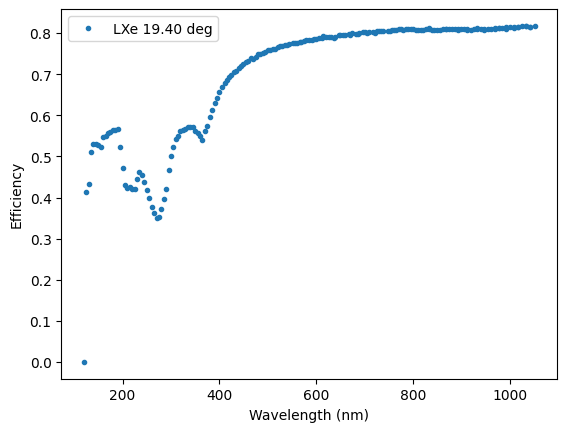

In [11]:
%matplotlib widget
%matplotlib inline

angles = dflxe['fAngle'].unique()
dflxe_specific = dflxe[dflxe["fAngle"] == angles[1]]
print(angles)

fig = plt.figure(figsize=(6, 4))
dflxe_specific.plot(x='fPhotonWln', y='eff', marker=".", linestyle="None", label=f"LXe {angles[1]:0.2f} deg")
plt.xlabel('Wavelength (nm)')
plt.ylabel('Efficiency')
plt.show()
# plt.close('all')


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_80850/4039266456.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('rainbow')


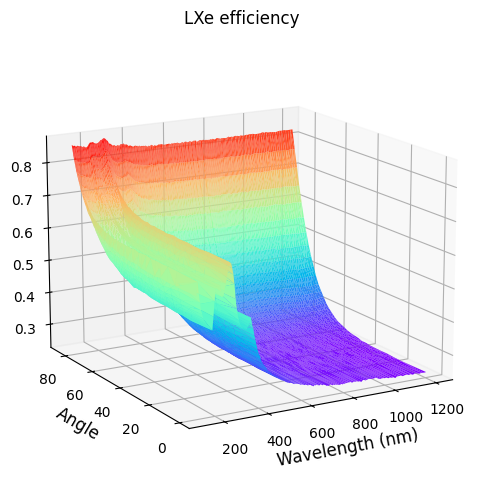

In [12]:
# %matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
cmap = plt.cm.get_cmap('rainbow')

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_trisurf(dfair.fPhotonWln, dfair.fAngle, 1-dfair.eff, cmap=cmap, linewidth=0.2)

ax.set_title('LXe efficiency')
ax.set_xlabel('Wavelength (nm)', fontsize=12)
ax.set_ylabel('Angle', fontsize=12)
ax.set_zlabel('Efficiency', fontsize=12, labelpad=500)

# Enable interactive rotation
ax.view_init(elev=15, azim=-120)

plt.show()


In [13]:
import numpy as np
for df in [dfair, dfcf4, dflxe]:
  print(df['fAngle'].unique()[0])
  angles = df["fAngle"].unique()
  # print(len())
  index = np.abs(angles - 60).argmin()
  print(index)
  print(df["fAngle"].unique()[index])

# Example array
arr = np.array([1, 3, 5, 7, 9])

# Number to find the closest entry to
num = 6

# Find the index of the closest entry
closest_index = np.abs(arr - num).argmin()

# Get the closest entry
closest_entry = arr[closest_index]

print(closest_entry)  # Output: 7
  
closestAngle = lambda df, angle: df["fAngle"].unique()[np.abs(df["fAngle"].unique() - angle).argmin()]
closestAngle(dfair, 60)



0.0
18
59.8998726919519
0.0
9
60.90025700225034
0.0
9
60.90025700225034
5


59.8998726919519

In [14]:
## picking zero degrees
%matplotlib inline
wl = "fPhotonWln" # for shorthand
getAngle = 0
dfAir_a0 = dfair[dfair["fAngle"] == closestAngle(dfair, getAngle)].drop_duplicates(subset="fPhotonWln")
dfcf4_a0 = dfcf4[dfcf4["fAngle"] == closestAngle(dfcf4, getAngle)].drop_duplicates(subset="fPhotonWln")
dflxe_a0 = dflxe[dflxe["fAngle"] == closestAngle(dflxe, getAngle)].drop_duplicates(subset="fPhotonWln")

getAngle = 60
dfAir_aS = dfair[dfair["fAngle"] == closestAngle(dfair, getAngle)].drop_duplicates(subset="fPhotonWln")
dfcf4_aS = dfcf4[dfcf4["fAngle"] == closestAngle(dfcf4, getAngle)].drop_duplicates(subset="fPhotonWln")
dflxe_aS = dflxe[dflxe["fAngle"] == closestAngle(dflxe, getAngle)].drop_duplicates(subset="fPhotonWln")

## picking LXe values
closest_lxeScint = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 175).argmin()]
print(closest_lxeScint)

dfAir_175 = dfair[dfair["fPhotonWln"] == closest_lxeScint].drop_duplicates(subset="fAngle")
dflxe_175 = dflxe[dflxe["fPhotonWln"] == closest_lxeScint].drop_duplicates(subset="fAngle")

closest_400 = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 400).argmin()]
print(closest_400)

dfAir_400 = dfair[dfair["fPhotonWln"] == closest_400].drop_duplicates(subset="fAngle")
dflxe_400 = dflxe[dflxe["fPhotonWln"] == closest_400].drop_duplicates(subset="fAngle")

## picking CF4 values
closest_300 = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 300).argmin()]
print(closest_300)

dfAir_300 = dfair[dfair["fPhotonWln"] == closest_300].drop_duplicates(subset="fAngle")
dfcf4_300 = dfcf4[dfcf4["fPhotonWln"] == closest_300].drop_duplicates(subset="fAngle")

## picking 650 nm
closest_650 = dfAir_a0[wl].values[np.abs(dfAir_a0[wl].values - 650).argmin()]
print(closest_650)

dfAir_650 = dfair[dfair["fPhotonWln"] == closest_650].drop_duplicates(subset="fAngle")
dfcf4_650 = dfcf4[dfcf4["fPhotonWln"] == closest_650].drop_duplicates(subset="fAngle")



174.87193008913997
399.9490272038717
300.2038702983056
649.1319289696347


In [15]:
smoothSigma = 3
gsmooth = lambda x: scipy.ndimage.gaussian_filter1d(input = x, sigma = smoothSigma)

# vs wavelength
f_air_0 = interpolate.interp1d(x = np.array(dfAir_a0[wl]), y = gsmooth(np.array(dfAir_a0["eff"])), kind = "cubic")
f_cf4_0 = interpolate.interp1d(x = np.array(dfcf4_a0[wl]), y = gsmooth(np.array(dfcf4_a0["eff"])), kind = "cubic")
f_lxe_0 = interpolate.interp1d(x = np.array(dflxe_a0[wl]), y = gsmooth(np.array(dflxe_a0["eff"])), kind = "cubic")

# vs angle (fixed lambda)
f_air_175 = interpolate.interp1d(x=np.array(dfAir_175["fAngle"]), y=np.array(dfAir_175["eff"]), kind="cubic")
f_lxe_175 = interpolate.interp1d(x=np.array(dflxe_175["fAngle"]), y=np.array(dflxe_175["eff"]), kind="cubic")
f_air_400 = interpolate.interp1d(x=np.array(dfAir_400["fAngle"]), y=np.array(dfAir_400["eff"]), kind="cubic")
f_lxe_400 = interpolate.interp1d(x=np.array(dflxe_400["fAngle"]), y=np.array(dflxe_400["eff"]), kind="cubic")

f_air_300 = interpolate.interp1d(x=np.array(dfAir_300["fAngle"]), y=np.array(dfAir_300["eff"]), kind="cubic")
f_air_650 = interpolate.interp1d(x=np.array(dfAir_650["fAngle"]), y=np.array(dfAir_650["eff"]), kind="cubic")
f_cf4_650 = interpolate.interp1d(x=np.array(dfcf4_650["fAngle"]), y=np.array(dfcf4_650["eff"]), kind="cubic")


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_80850/2789707123.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


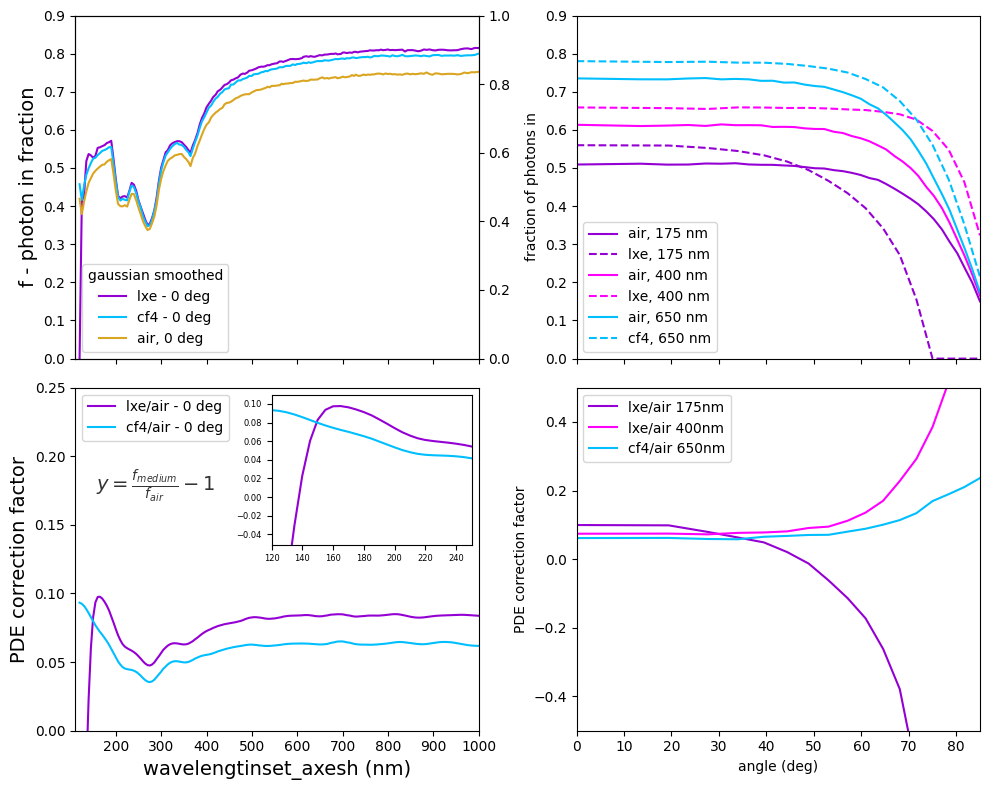

In [35]:
# Plot the data frames on the same canvas
fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, sharex='col', figsize=(10, 8))

# top left
dflxe_a0.plot(x="fPhotonWln", y="eff", kind="line", label="lxe - 0 deg", color = ms.lxe.col, ax = ax1)
dfcf4_a0.plot(x="fPhotonWln", y="eff", kind="line", label="cf4 - 0 deg", color = ms.cf4.col, ax = ax1)
dfAir_a0.plot(x="fPhotonWln", y="eff", kind="line", label='air, 0 deg', color = ms.air.col, ax = ax1)

ax1p = ax1.twinx()

# dfAir_aS.plot(x="fPhotonWln", y="eff", kind="line", label=f'air, {dfAir_aS["fAngle"].iloc[0]:0.2f} deg', ax = ax1p)
# dfcf4_aS.plot(x="fPhotonWln", y="eff", kind="line", label=f'cf4, {dfcf4_aS["fAngle"].iloc[0]} deg', ax = ax1)
# dflxe_aS.plot(x="fPhotonWln", y="eff", kind="line", label=f'lxe, {dflxe_aS["fAngle"].iloc[0]} deg', ax = ax1)

ax1.set_ylim(0.0, 0.9)
ax1.set_xlim(110, 1000)

#ax2 bottom left - correction
xCF4 = dfcf4_a0["fPhotonWln"]
xwl = np.arange(min(xCF4), max(xCF4), 10)
ax2.plot(xCF4, f_lxe_0(xCF4)/f_air_0(xCF4)-1, color = ms.lxe.col, label="lxe/air - 0 deg")
ax2.plot(xCF4, f_cf4_0(xCF4)/f_air_0(xCF4)-1, color = ms.cf4.col, label="cf4/air - 0 deg")
ax2.set_ylim(0, 0.25)

# ax 3 - eff vs angle (top right)
dfAir_175.plot(x="fAngle", y="eff", kind="line", color = ms.lxe.col, linestyle = ms.line1, label='air, 175 nm', ax = ax3)
dflxe_175.plot(x="fAngle", y="eff", kind="line", color = ms.lxe.col, linestyle = ms.line2, label="lxe, 175 nm", ax = ax3)

dfAir_400.plot(x="fAngle", y="eff", kind="line", color = ms.lxe2.col, linestyle = ms.line1, label='air, 400 nm', ax = ax3)
dflxe_400.plot(x="fAngle", y="eff", kind="line", color = ms.lxe2.col, linestyle = ms.line2, label="lxe, 400 nm", ax = ax3)

dfAir_650.plot(x="fAngle", y="eff", kind="line", color= ms.cf4.col, linestyle = ms.line1, label='air, 650 nm', ax = ax3)
dfcf4_650.plot(x="fAngle", y="eff", kind="line", color= ms.cf4.col, linestyle = ms.line2, label="cf4, 650 nm", ax = ax3)
ax3.set_ylim(0, 0.9)
ax3.set_xlim(0, 85)
# ax3.set_ylim(0., 0.15)

# ax4 bottom right - angle correction
xAngLxe = dflxe_175["fAngle"]
ax4.plot(xAngLxe, f_lxe_175(xAngLxe)/f_air_175(xAngLxe)-1, color = ms.lxe.col, label="lxe/air 175nm")
ax4.plot(xAngLxe, f_lxe_400(xAngLxe)/f_air_400(xAngLxe)-1, color = ms.lxe2.col, label="lxe/air 400nm")
ax4.plot(xAngLxe, f_cf4_650(xAngLxe)/f_air_650(xAngLxe)-1, color = ms.cf4.col, label="cf4/air 650nm")
ax4.set_ylim(-0.5, 0.5)


#### formatting
fs = 14
ax1.set_ylabel("f - photon in fraction", fontsize = fs)
ax1.set_xlabel("wavelength (nm)", fontsize = fs)
ax1.legend(title="gaussian smoothed")

ax2.text(0.2, 0.7, r"$y = \frac{f_{medium}}{f_{air}} - 1$", transform=ax2.transAxes, ha='center', fontsize=14, alpha = 0.8)

ax2.set_ylabel("PDE correction factor", fontsize = fs)
ax2.set_xlabel("wavelengtinset_axesh (nm)", fontsize = fs)
ax2.legend(loc="upper left")

ax3.set_ylabel("fraction of photons in")
ax3.set_xlabel("angle (deg)")

ax4.legend()
ax4.set_ylabel("PDE correction factor")
ax4.set_xlabel("angle (deg)")

# Add "preliminary" text at 45 degrees
# fig.text(0.5, 0.5, "preliminary", color='red', alpha=0.1, rotation=45, ha='center', va='center', fontsize=60)

ax1.set_xlim(110, 1000)

# zoom in must be done at bottom
axins = inset_axes(ax2, width=2, height=1.5, loc='upper right', bbox_to_anchor=(1, 1), bbox_transform=ax2.transAxes)
axins.plot(xCF4, f_lxe_0(xCF4)/f_air_0(xCF4)-1, color = ms.lxe.col)
axins.plot(xCF4, f_cf4_0(xCF4)/f_air_0(xCF4)-1, color = ms.cf4.col)
axins.set_xlim(120, 250)
axins.set_ylim(-0.051, 0.11)
axins.tick_params(axis='x', labelsize=6)
axins.tick_params(axis='y', labelsize=6)

# Show the plot
plt.tight_layout()
plt.show()



In [ ]:
# # print(type(tt))
# # print(tt.keys())
# # np = tt.arrays("fNphoton")
# # tt.num_entries


# wlPDE, pde = np.loadtxt(os.path.join(opticsPath, "SiPMeff_Ham_5V.dat"), skiprows=1, unpack = True)
# pde *= 1/100

# start = 9
# pdeScaledUp = pde[start:]/fairEff_0(wlPDE[start:])
# pdeScaledBack = pdeScaledUp*fcf4Eff_0(wlPDE[start:])  

# # are the optics dominated by the thin film or the bulk                         

# plt.plot(wlPDE, pde, label = "regular PDE")
# plt.plot(wlPDE[start:], pdeScaledUp, label = "scaled up")
# plt.plot(wlPDE[start:], pdeScaledBack, label = "after CF4 optics")
# plt.legend()

# plt.show()